# Student Performance Analysis Using Python

## 1. Introduction

Student academic performance is influenced by several factors, including study habits, previous academic results, family background, educational support, and school-related conditions.

The objective of this project is to explore and analyze student academic performance using Python and data analysis techniques. The project uses the Student Performance dataset from the UCI Machine Learning Repository, focusing on students' Mathematics grades.

The dataset contains information about 395 students and 33 attributes, including demographic details, family background, study time, absences, previous failures, and examination grades.

### Project Objectives

- Understand and inspect the student performance dataset.
- Identify missing values, duplicate records, and unusual observations.
- Analyze the relationship between study habits and academic performance.
- Explore how family, school, and social factors relate to final grades.
- Perform statistical analysis and correlation analysis.
- Create meaningful visualizations to communicate findings.
- Draw conclusions based on the exploratory data analysis.

### Tools and Technologies

- **Python** – Programming language.
- **Pandas** – Data manipulation and analysis.
- **NumPy** – Numerical operations.
- **Matplotlib** – Data visualization.
- **Seaborn** – Statistical visualization.
- **Jupyter Notebook** – Development environment.

### Dataset Information

- **Dataset:** Student Performance (Mathematics)
- **Source:** UCI Machine Learning Repository
- **Records:** 395 students
- **Attributes:** 33 columns
- **Target variable:** G3 (Final Mathematics Grade)
- **Grade scale:** 0–20

### Project Approach

This project follows an Exploratory Data Analysis (EDA) approach, including data inspection, data quality checks, statistical summaries, group comparisons, correlation analysis, and visualizations to understand patterns in student academic performance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../dataset/student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
print("Rows and Columns:",df.shape)

Rows and Columns: (395, 33)


In [4]:
print(df.columns.tolist())

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [5]:
print("Total Student:", df.shape[0]) #Number of rows in the Dataset
print("Total Features:",df.shape[1]) #Number of Columns in the Dataset

Total Student: 395
Total Features: 33


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [7]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [8]:
df["G3"].describe()

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

In [9]:
missing_values = df.isnull().sum()
print("missing_values:\n", missing_values)
print("Total Missing Values:", df.isnull().sum().sum())

missing_values:
 school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Total Missing Values: 0


In [10]:
duplicate_rows_count = df.duplicated().sum()
print("Total Duplicate Records: ",duplicate_rows_count)

Total Duplicate Records:  0


In [11]:
for column in df.columns:
    print(column,":",df[column].nunique())

school : 2
sex : 2
age : 8
address : 2
famsize : 2
Pstatus : 2
Medu : 5
Fedu : 5
Mjob : 5
Fjob : 5
reason : 4
guardian : 3
traveltime : 4
studytime : 4
failures : 4
schoolsup : 2
famsup : 2
paid : 2
activities : 2
nursery : 2
higher : 2
internet : 2
romantic : 2
famrel : 5
freetime : 5
goout : 5
Dalc : 5
Walc : 5
health : 5
absences : 34
G1 : 17
G2 : 17
G3 : 18


In [12]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [13]:
Columns_to_check = [
    "age","studytime","failures","absences","G1","G2","G3"
]
for column in Columns_to_check:
    print(column,"-",
          "Minimum:",df[column].min(),
          "Maximum:",df[column].max()
          
          )

age - Minimum: 15 Maximum: 22
studytime - Minimum: 1 Maximum: 4
failures - Minimum: 0 Maximum: 3
absences - Minimum: 0 Maximum: 75
G1 - Minimum: 3 Maximum: 19
G2 - Minimum: 0 Maximum: 19
G3 - Minimum: 0 Maximum: 20


In [14]:
print("Invalid studytime values:")
print(df[~df["studytime"].between(1,4)])
print("\nInvalid G3 values:")
print(df[~df["G3"].between(0,20)])

Invalid studytime values:
Empty DataFrame
Columns: [school, sex, age, address, famsize, Pstatus, Medu, Fedu, Mjob, Fjob, reason, guardian, traveltime, studytime, failures, schoolsup, famsup, paid, activities, nursery, higher, internet, romantic, famrel, freetime, goout, Dalc, Walc, health, absences, G1, G2, G3]
Index: []

[0 rows x 33 columns]

Invalid G3 values:
Empty DataFrame
Columns: [school, sex, age, address, famsize, Pstatus, Medu, Fedu, Mjob, Fjob, reason, guardian, traveltime, studytime, failures, schoolsup, famsup, paid, activities, nursery, higher, internet, romantic, famrel, freetime, goout, Dalc, Walc, health, absences, G1, G2, G3]
Index: []

[0 rows x 33 columns]


In [15]:
print("Absences Summary")

print("Minimum:",df["absences"].min())
print("Q1:", df["absences"].quantile(0.25))
print("Median:",df["absences"].median())
print("Q3:", df["absences"].quantile(0.75))
print("Maximum:",df["absences"].max())

Absences Summary
Minimum: 0
Q1: 0.0
Median: 4.0
Q3: 8.0
Maximum: 75


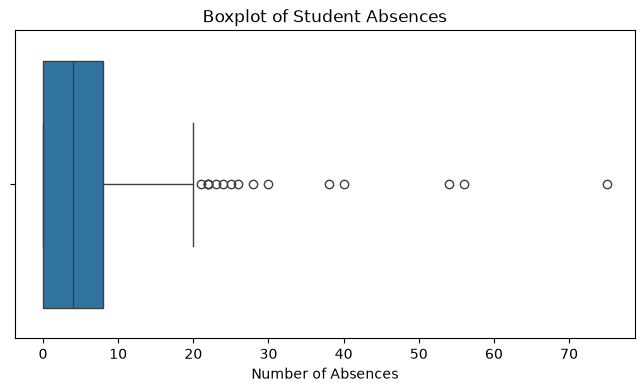

In [16]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df["absences"])
plt.title("Boxplot of Student Absences")
plt.xlabel("Number of Absences")
plt.show()

In [17]:
Q1 = df["absences"].quantile(0.25)
Q3 = df["absences"].quantile(0.75)

#Calculate the IQR
IQR = Q3 - Q1
#Calculate the Boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Q1: 0.0
Q3: 8.0
IQR: 8.0
Lower Bound: -12.0
Upper Bound: 20.0


In [18]:
outliers = df[
    (df["absences"]<lower_bound) | (df["absences"]>upper_bound)
]

print("Total Potential Outliers:", len(outliers))
outliers[["age","studytime","absences","G1","G2","G3"]]

Total Potential Outliers: 15


,age,studytime,absences,G1,G2,G3
40,16,2,25,7,10,11
74,16,2,54,11,12,11
103,15,2,26,7,6,6
183,17,2,56,9,9,8
198,17,1,24,18,18,18
205,17,3,28,10,9,9
216,17,2,22,6,6,4
260,18,2,21,17,18,18
276,18,2,75,10,9,9
277,18,1,22,9,9,9


In [19]:
study_analysis = df.groupby("studytime")["G3"].mean()
print(study_analysis)

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


In [20]:
study_count = df["studytime"].value_counts().sort_index()
print(study_count)

studytime
1    105
2    198
3     65
4     27
Name: count, dtype: int64


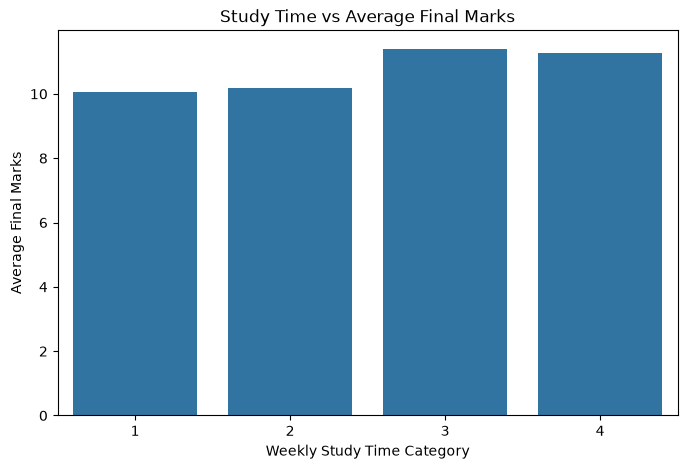

In [21]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=study_analysis.index,
    y=study_analysis.values
)

plt.title("Study Time vs Average Final Marks")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Average Final Marks")


plt.show()

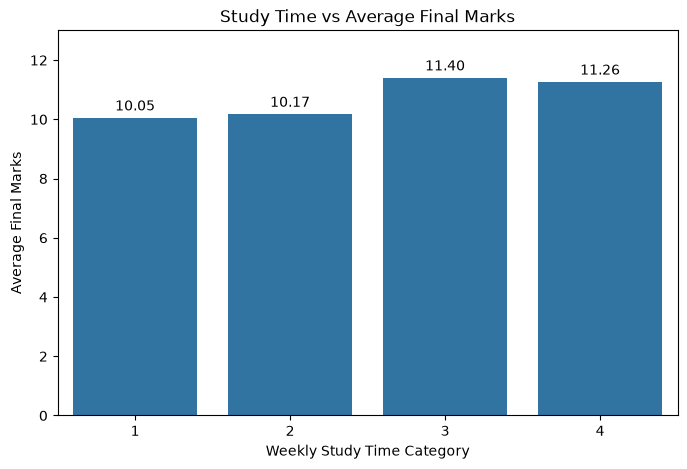

In [22]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=study_analysis.index,
    y=study_analysis.values
)
#Display values above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Study Time vs Average Final Marks")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Average Final Marks")

plt.ylim(0,13)

plt.savefig(
    "../Visualizations/Study_Time_vs_Grade.png",
    dpi=300,
    bbox_inches = "tight"
)

plt.show()

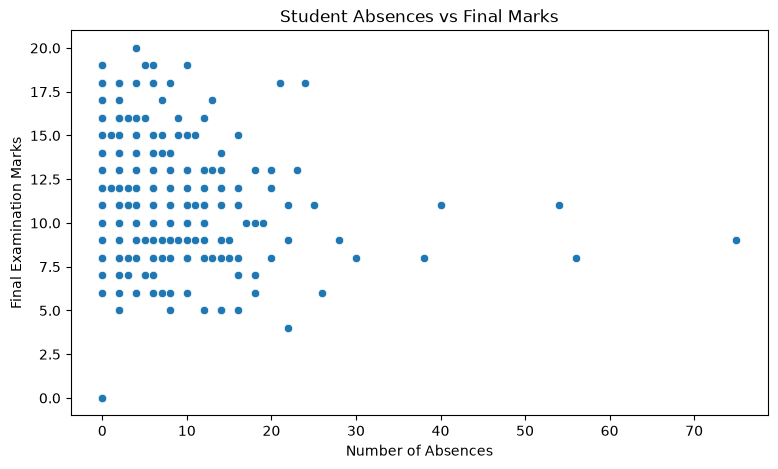

In [23]:
plt.figure(figsize=(9, 5)) #figsize(width , height)

sns.scatterplot(
    data=df,
    x="absences",
    y="G3"
)

plt.title("Student Absences vs Final Marks")
plt.xlabel("Number of Absences")
plt.ylabel("Final Examination Marks")

plt.savefig(
    "../Visualizations/Absences_vs_Grade.png",
    dpi=300,
    bbox_inches = "tight"
)

plt.show()

In [24]:
correlation = df["absences"].corr(df["G3"])

print("Absences vs Final Marks Correlation:", correlation)

Absences vs Final Marks Correlation: 0.03424731615006933


In [25]:
# Correlation using all students
corr_all = df["absences"].corr(df["G3"])

# Temporarily exclude potential absence outliers
df_without_outliers = df[df["absences"] <= upper_bound]

corr_without_outliers = (
    df_without_outliers["absences"].corr(
        df_without_outliers["G3"]
    )
)

print("Correlation with all students:", corr_all)

print("Correlation without potential outliers:",
      corr_without_outliers)

Correlation with all students: 0.03424731615006933
Correlation without potential outliers: 0.08446691191361909


In [26]:
gender_count = df["sex"].value_counts()

print("Gender Distribution:")
print(gender_count)

gender_analysis = df.groupby("sex")["G3"].mean()

print("\nAverage Final Marks by Gender:")
print(gender_analysis)

gender_summary = df.groupby("sex")["G3"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(gender_summary)

Gender Distribution:
sex
F    208
M    187
Name: count, dtype: int64

Average Final Marks by Gender:
sex
F     9.966346
M    10.914439
Name: G3, dtype: float64
     count       mean  median  min  max
sex                                    
F      208   9.966346    10.0    0   19
M      187  10.914439    11.0    0   20


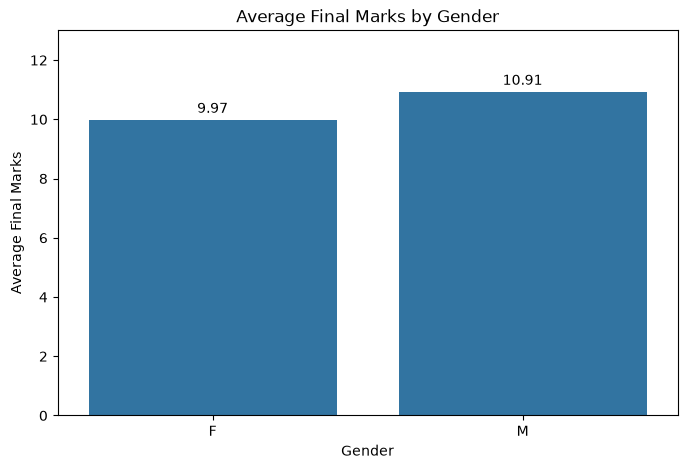

In [27]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=gender_analysis.index,
    y=gender_analysis.values
)

# Add values above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Average Final Marks by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Final Marks")
plt.ylim(0, 13)

plt.savefig(
    "../Visualizations/Gender_vs_Grade.png",
    dpi=300,
    bbox_inches = "tight"
)
plt.show()

In [28]:
grade_analysis = df[["G1","G2","G3"]].corr()
print(grade_analysis)

          G1        G2        G3
G1  1.000000  0.852118  0.801468
G2  0.852118  1.000000  0.904868
G3  0.801468  0.904868  1.000000


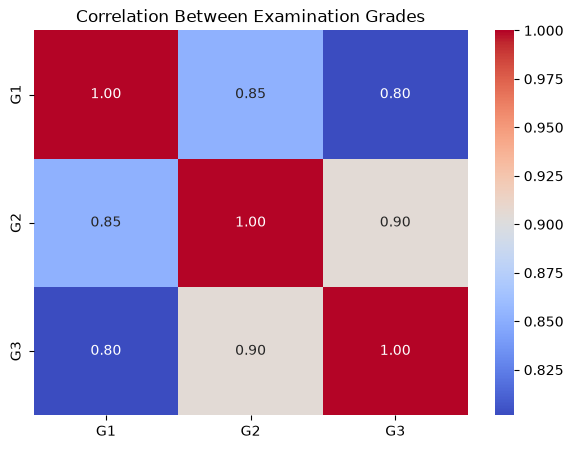

In [29]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    grade_analysis,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Examination Grades")
plt.savefig(
    "../Visualizations/Grade_Correlation_heatmap.png",
    dpi=300,
    bbox_inches = "tight"
)
plt.show()

In [30]:
# Count students according to their final marks
grade_distribution = df["G3"].value_counts().sort_index()

print(grade_distribution)

G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64


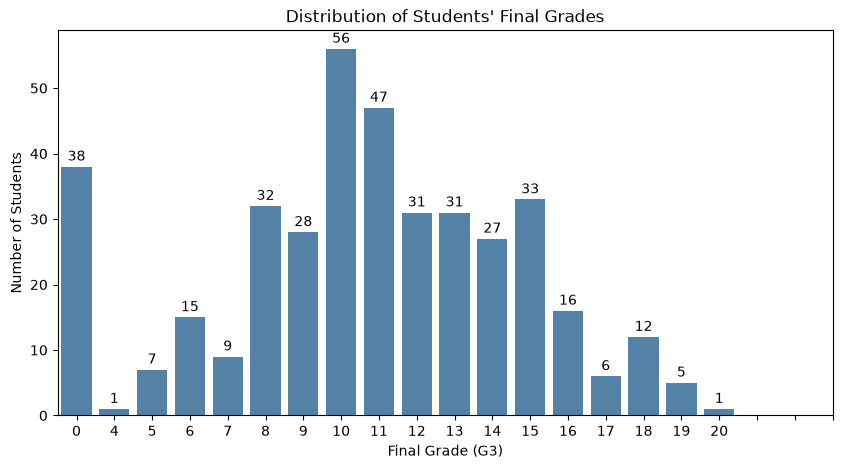

In [31]:
plt.figure(figsize=(10, 5))

ax = sns.countplot(data=df, x="G3", color="steelblue")

for container in ax.containers:
    ax.bar_label(container, padding=2)

plt.title("Distribution of Students' Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.xticks(range(0, 21))

plt.savefig(
    "../Visualizations/Grade_distribution.png",
    dpi=300,
    bbox_inches = "tight"
)
plt.show()

In [32]:
# Classify students based on final marks
df["result"] = np.where(df["G3"] < 10, "Below 10", "10 or Above")

# Count students in each group
result_count = df["result"].value_counts()

print(result_count)

result
10 or Above    265
Below 10       130
Name: count, dtype: int64


In [33]:
failure_analysis = df.groupby("failures")["G3"].agg(
    ["count", "mean", "median"]
)

print(failure_analysis)

          count       mean  median
failures                          
0           312  11.253205    11.0
1            50   8.120000     9.0
2            17   6.235294     8.0
3            16   5.687500     7.0


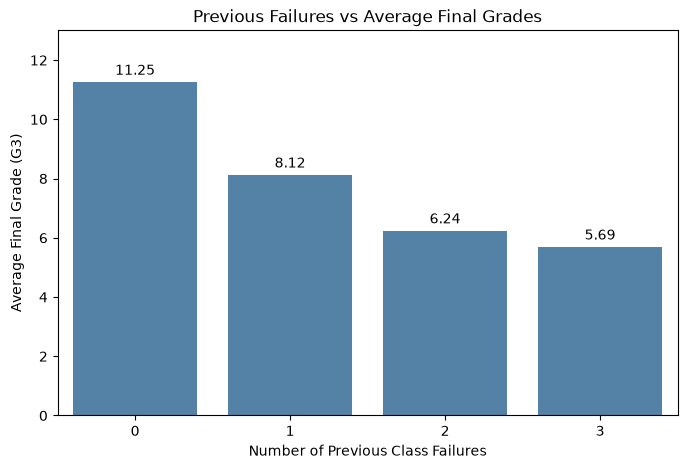

In [34]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="failures",
    y="G3",
    color="steelblue",
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Previous Failures vs Average Final Grades")
plt.xlabel("Number of Previous Class Failures")
plt.ylabel("Average Final Grade (G3)")
plt.ylim(0, 13)
plt.savefig(
    "../Visualizations/Previous_Failures_vs_Grade.png",
    dpi=300,
    bbox_inches = "tight"
)
plt.show()

In [35]:
parent_education = df.groupby(["Medu", "Fedu"])["G3"].mean().reset_index()

print(parent_education.head(10))

   Medu  Fedu         G3
0     0     1   9.000000
1     0     2  15.000000
2     1     0  16.000000
3     1     1   8.297297
4     1     2   9.333333
5     1     3   7.200000
6     1     4  13.000000
7     2     1   9.214286
8     2     2   9.333333
9     2     3  10.529412


In [36]:
parent_education = df.groupby(["Medu", "Fedu"])["G3"].agg(
    ["count", "mean", "median"]
).reset_index()

print(parent_education.head(15))

    Medu  Fedu  count       mean  median
0      0     1      1   9.000000     9.0
1      0     2      2  15.000000    15.0
2      1     0      1  16.000000    16.0
3      1     1     37   8.297297    10.0
4      1     2     15   9.333333    11.0
5      1     3      5   7.200000     8.0
6      1     4      1  13.000000    13.0
7      2     1     28   9.214286    10.0
8      2     2     51   9.333333    11.0
9      2     3     17  10.529412    11.0
10     2     4      7  12.714286    13.0
11     3     1     15  11.266667    10.0
12     3     2     28  10.321429    10.5
13     3     3     38  10.236842    10.0
14     3     4     18   9.611111    11.0


In [37]:
# Mother's education vs student performance
mother_analysis = df.groupby("Medu")["G3"].agg(
    ["count", "mean", "median"]
)

# Father's education vs student performance
father_analysis = df.groupby("Fedu")["G3"].agg(
    ["count", "mean", "median"]
)

print("Mother's Education vs Final Grade")
print(mother_analysis)

print("\nFather's Education vs Final Grade")
print(father_analysis)

Mother's Education vs Final Grade
      count       mean  median
Medu                          
0         3  13.000000    15.0
1        59   8.677966    10.0
2       103   9.728155    11.0
3        99  10.303030    10.0
4       131  11.763359    12.0

Father's Education vs Final Grade
      count       mean  median
Fedu                          
0         2  13.000000    13.0
1        82   9.158537    10.0
2       115  10.260870    11.0
3       100  10.660000    10.0
4        96  11.364583    12.0


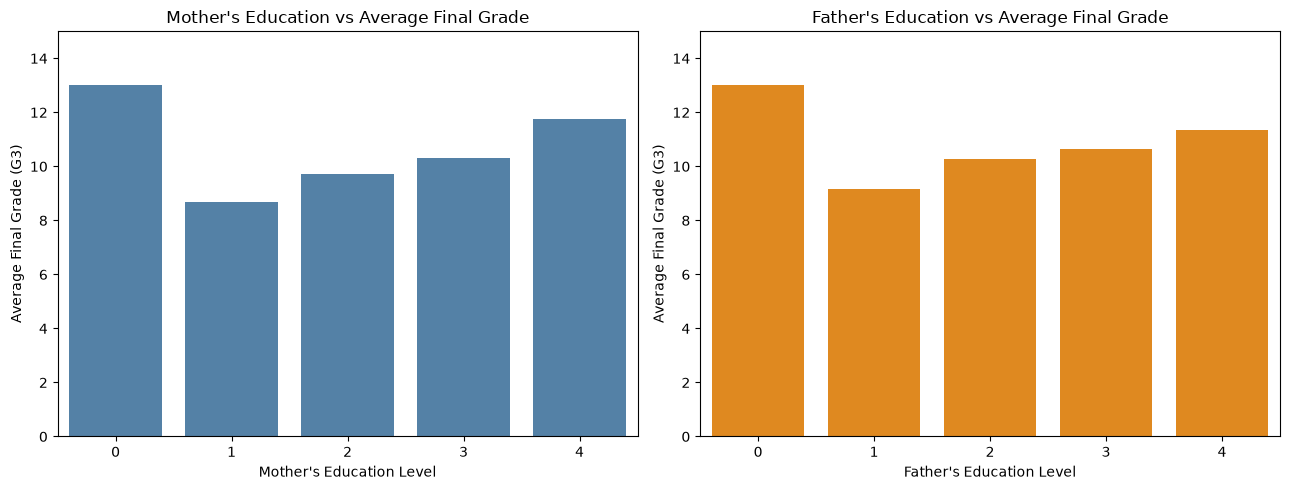

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Mother's education
sns.barplot(
    x=mother_analysis.index,
    y=mother_analysis["mean"],
    ax=axes[0],
    color="steelblue",
    errorbar=None
)

axes[0].set_title("Mother's Education vs Average Final Grade")
axes[0].set_xlabel("Mother's Education Level")
axes[0].set_ylabel("Average Final Grade (G3)")
axes[0].set_ylim(0, 15)

# Father's education
sns.barplot(
    x=father_analysis.index,
    y=father_analysis["mean"],
    ax=axes[1],
    color="darkorange",
    errorbar=None
)

axes[1].set_title("Father's Education vs Average Final Grade")
axes[1].set_xlabel("Father's Education Level")
axes[1].set_ylabel("Average Final Grade (G3)")
axes[1].set_ylim(0, 15)

plt.tight_layout()
plt.savefig(
    "../Visualizations/Parental_education_vs_Grade.png",
    dpi=300,
    bbox_inches = "tight"
)
plt.show()

In [39]:
family_support_analysis = df.groupby("famsup")["G3"].agg(
    ["count", "mean", "median"]
)

print(family_support_analysis)

        count       mean  median
famsup                          
no        153  10.640523    11.0
yes       242  10.272727    11.0


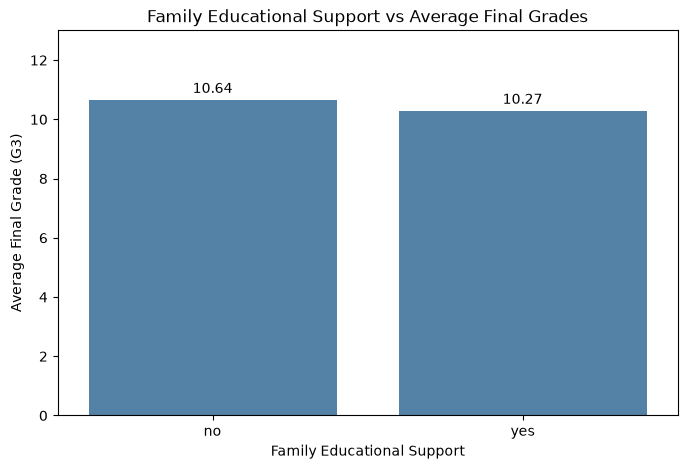

In [40]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="famsup",
    y="G3",
    color="steelblue",
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Family Educational Support vs Average Final Grades")
plt.xlabel("Family Educational Support")
plt.ylabel("Average Final Grade (G3)")
plt.ylim(0, 13)
plt.savefig(
    "../Visualizations/Family_support_vs_Grade.png",
    dpi=300,
    bbox_inches = "tight"
)
plt.show()

In [41]:
school_support_analysis = df.groupby("schoolsup")["G3"].agg(
    ["count", "mean", "median"]
)

print(school_support_analysis)

           count       mean  median
schoolsup                          
no           344  10.561047    11.0
yes           51   9.431373    10.0


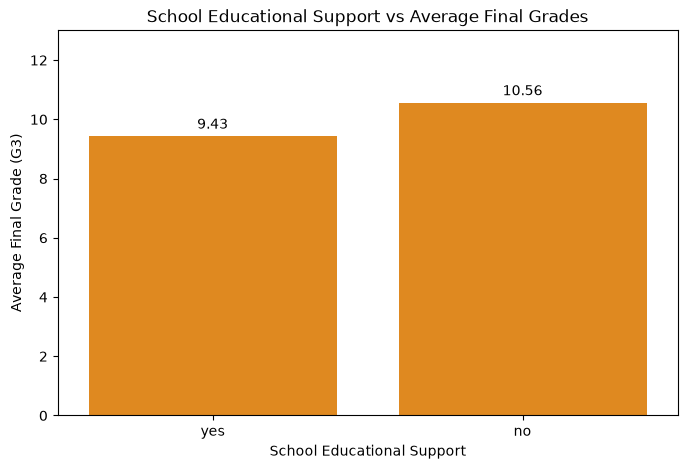

In [42]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="schoolsup",
    y="G3",
    color="darkorange",
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("School Educational Support vs Average Final Grades")
plt.xlabel("School Educational Support")
plt.ylabel("Average Final Grade (G3)")
plt.ylim(0, 13)
plt.savefig(
    "../Visualizations/School_support_vs_Grade.png",
    dpi=300,
    bbox_inches = "tight"
)
plt.show()

In [43]:
travel_analysis = df.groupby("traveltime")["G3"].agg(
    ["count", "mean", "median"]
)

print(travel_analysis)

            count       mean  median
traveltime                          
1             257  10.782101    11.0
2             107   9.906542    10.0
3              23   9.260870    10.0
4               8   8.750000    10.0


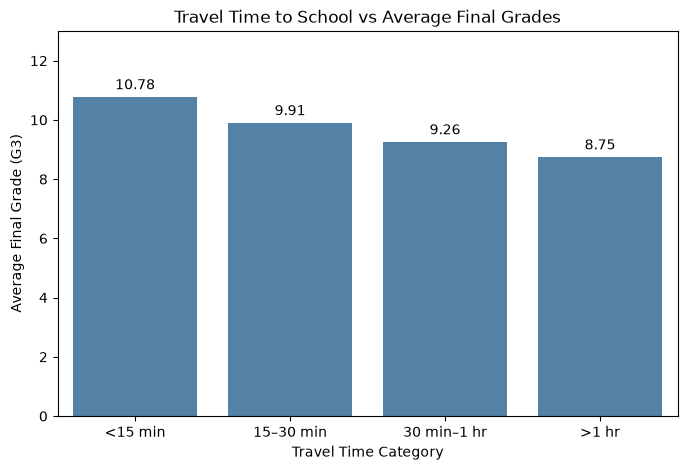

In [44]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="traveltime",
    y="G3",
    color="steelblue",
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Travel Time to School vs Average Final Grades")
plt.xlabel("Travel Time Category")
plt.ylabel("Average Final Grade (G3)")
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=["<15 min", "15–30 min", "30 min–1 hr", ">1 hr"]
)
plt.ylim(0, 13)
plt.savefig(
    "../Visualizations/Travel_time_vs_Grade.png",
    dpi=300,
    bbox_inches = "tight"
)
plt.show()


In [45]:
final_summary = df[[
    "G1", "G2", "G3", "studytime",
    "absences", "failures", "traveltime"
]].describe()

print(final_summary.round(2))

           G1      G2      G3  studytime  absences  failures  traveltime
count  395.00  395.00  395.00     395.00    395.00    395.00      395.00
mean    10.91   10.71   10.42       2.04      5.71      0.33        1.45
std      3.32    3.76    4.58       0.84      8.00      0.74        0.70
min      3.00    0.00    0.00       1.00      0.00      0.00        1.00
25%      8.00    9.00    8.00       1.00      0.00      0.00        1.00
50%     11.00   11.00   11.00       2.00      4.00      0.00        1.00
75%     13.00   13.00   14.00       2.00      8.00      0.00        2.00
max     19.00   19.00   20.00       4.00     75.00      3.00        4.00


## Conclusion

This project analyzed the academic performance of 395 students using Python, Pandas, NumPy, Matplotlib, and Seaborn. The UCI Student Performance dataset for Mathematics was used to explore relationships between students' final grades and different academic, family, and social factors.

The analysis found that previous examination grades, particularly the second-period grade (G2), had a strong positive relationship with final performance (G3). Students with more previous class failures generally had lower average final grades. Study time, parental education, and travel time also showed patterns associated with academic performance.

Interestingly, students receiving family or school educational support had slightly lower average grades than students who did not receive such support. This does not indicate that support negatively affects performance; students experiencing academic difficulties may be more likely to receive additional support.

The analysis of absences showed almost no linear correlation with final grades in this dataset. Overall, the findings demonstrate that academic performance is associated with several factors and that no single factor should be considered independently.

This project provided practical experience in data loading, inspection, cleaning, exploratory data analysis, statistical summaries, correlation analysis, and data visualization using Python libraries.


## Future Scope

1. Apply Machine Learning algorithms to predict student performance.
2. Include datasets from more schools and subjects.
3. Explore additional factors affecting academic performance.
4. Compare multiple ML models using appropriate evaluation metrics.
5. Develop an interactive dashboard for visualizing student performance.
6. Build an early-warning system to identify students who may need academic support.

## Project Limitations

1. The dataset contains only 395 students.
2. The analysis focuses only on Mathematics performance.
3. The findings may not represent all schools or student populations.
4. Some categories have very small sample sizes.
5. Correlation and group comparisons do not establish causation.
6. The project uses exploratory data analysis and does not establish predictive accuracy.